# NOTEBOOK 8: Presentation figures from the analysis results — OSD-420

**The Spleen Machine (OSD-420-3)** · Kireeti, Pranav, Aryan, Vedant · Interlake High School

Every data figure in the capstone deck is built here. Each one is drawn at the size it is
displayed at on the slide, so the point sizes you set are the point sizes the audience sees.
Scaling a figure down inside PowerPoint is what turns 13pt axis labels into 6pt ones.

## What this notebook needs

It reads the CSV files written by **Notebook 6** (differential expression) and **Notebook 7**
(pathways). Run those first, or place their `results/` folder next to this notebook.

| File | Written by | Used for |
|---|---|---|
| `results/deseq2_full_results.csv` | NB6 | volcano, modules, heme, contamination |
| `results/normalized_counts.csv` | NB6 | QC PCA |
| `results/vst_counts.csv` | NB6 | QC PCA |
| `results/sample_metadata.csv` | NB6 | group labels |
| `results/pca.json` | NB6 | variance explained, depth correlation |
| `results/contamination_scores.csv` | NB6 | contamination QC panel |
| `results/pathways/gsea_significant.csv` | NB7 | GSEA bar chart |
| `results/pathways/gsea_leading_edge_genes.csv` | NB7 | heme leading edge |

## On the colour palette

Three categorical hues carry the three modules: teal-green `#14876b`, terracotta `#a34517`,
plum `#7c42ab`. They were checked with a colourblindness validator against a white surface —
worst-pair separation is ΔE 9.8 under deuteranopia and 22.2 under normal vision. Every
colour-coded series is also directly labelled, so nothing in the deck depends on colour alone.
That is a 508 accessibility requirement, not a preference.

## Setup

`Agg` is the non-interactive matplotlib backend, which is what you want when the job is to write
PNG files rather than to draw on screen. Each figure is displayed inline afterwards so you can
check it here.

In [1]:
#!/usr/bin/env python3
"""
Presentation figures for OSD-420. Each figure is built for one specific slide and
one specific sentence the presenter has to say.

Palette: validated categorical set (blue #2a78d6, orange #eb6834, aqua #1baf7a)
and diverging pair (blue up / red #e34948 down), checked with the dataviz
validator for CVD separation and normal-vision separation on a light surface.
Every colour-coded series is also directly labelled, so identity is never
carried by colour alone.
"""
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

OUT = "results"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)

# ---- design tokens ----------------------------------------------------------
SURFACE = "#ffffff"
INK = "#171310"
INK2 = "#574e43"
MUTED = "#8c8175"
GRID = "#e7decc"
BLUE = "#14876b"      # teal-green
ORANGE = "#a34517"    # terracotta
AQUA = "#7c42ab"      # plum
RED = "#a34517"       # terracotta (down in flight)
VIOLET = "#6e655b"    # neutral, for the non-module theme
NEUTRAL = "#cfc6b6"

plt.rcParams.update({
    "font.family": "Carlito",           # metric-compatible with Calibri
    "font.size": 13,
    "axes.edgecolor": GRID,
    "axes.linewidth": 1.0,
    "axes.labelcolor": INK2,
    "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "legend.frameon": True, "legend.framealpha": 1.0,
    "legend.facecolor": SURFACE, "legend.edgecolor": "none", "legend.borderpad": 0.35,
    "axes.spines.top": False, "axes.spines.right": False,
})
DPI = 300


def finish(fig, name):
    p = f"{FIG}/{name}.png"
    fig.savefig(p, dpi=DPI, bbox_inches="tight", pad_inches=0.12)
    plt.close(fig)
    print("  wrote", p)


res = pd.read_csv(f"{OUT}/deseq2_full_results.csv", index_col=0)
tested = res[res["padj"].notna()].copy()
sig = tested[tested["padj"] < 0.05].copy()
pca = json.load(open(f"{OUT}/pca.json"))
contam = pd.read_csv(f"{OUT}/contamination_scores.csv")
gsea = pd.read_csv(f"{OUT}/pathways/gsea_significant.csv")
ora = pd.read_csv(f"{OUT}/pathways/ora_significant.csv")
mods = pd.read_csv(f"{OUT}/module_statistics.csv")
led = pd.read_csv(f"{OUT}/pathways/gsea_leading_edge_genes.csv")

MODULES = {
    "Stromal / perivascular": (["Gpx3", "Sparcl1", "Aebp1", "Wt1", "Pdgfra", "Cxcl12"], BLUE),
    "Erythroid / heme": (["Trim10", "Gypa", "Ahsp", "Hmbs", "Alas2", "Slc4a1"], ORANGE),
    "Type I interferon": (["Rsad2", "Isg15", "Ifit1", "Ifi27l2a", "Mx1", "Stat1"], AQUA),
}

print("Building figures ...")

Building figures ...


## Check the inputs are present

If this cell fails, run Notebook 6 and Notebook 7 first.

In [2]:
import os

need = [
    "results/deseq2_full_results.csv",
    "results/normalized_counts.csv",
    "results/vst_counts.csv",
    "results/sample_metadata.csv",
    "results/pca.json",
    "results/contamination_scores.csv",
    "results/pathways/gsea_significant.csv",
    "results/pathways/gsea_leading_edge_genes.csv",
]
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(
        "Run Notebook 6 and Notebook 7 first. Missing:\n  " + "\n  ".join(missing))
print(f"All {len(need)} input files present.")

All 8 input files present.


## Figure 3 — quality control before testing

Two panels, and the left one is the argument.

**Left:** PC1 of the raw counts against library size. Spearman ρ = +0.988. Before touching any
biology, this says the largest axis of variation in the raw data is how deeply each sample was
sequenced. Any filter applied to raw counts inherits that, which is exactly how the old
coefficient-of-variation filter became a sequencing-depth filter in disguise.

**Right:** the same samples after variance-stabilising transformation. Flight and ground do not
separate (p = 0.38). Showing this rather than hiding it sets the expectation for the rest of the
talk: the effect is coordinated and subtle, not dramatic.

In [3]:
# Slide: preliminary data / methods.
# The sentence: "Before we looked at a single gene we asked what our biggest axis
#  of variation actually was -- and on raw counts it is sequencing depth."
fig = plt.figure(figsize=(7.6, 3.30))
gs_ = fig.add_gridspec(1, 2, wspace=0.36, left=0.10, right=0.99, top=0.76, bottom=0.19)
libsize = contam.set_index("sample")["lib_size"]

axL = fig.add_subplot(gs_[0, 0])
d = pca["raw"]
Y = np.array(d["coords"]); samples = d["samples"]; ev = d["ev"]
depth = libsize.reindex(samples).values / 1e6
sc = axL.scatter(Y[:, 0] / 1e6, depth, s=64, c=depth, cmap="YlOrBr", vmin=2, vmax=52,
                 edgecolor=INK2, linewidth=0.7, zorder=3)
zz = np.polyfit(Y[:, 0] / 1e6, depth, 1)
xs = np.linspace((Y[:, 0] / 1e6).min(), (Y[:, 0] / 1e6).max(), 20)
axL.plot(xs, np.polyval(zz, xs), color=MUTED, linewidth=1.4, linestyle=(0, (5, 4)), zorder=2)
axL.set_xlabel(f"PC1 on raw counts  ({ev[0]*100:.1f}% of variance)", fontsize=12.5)
axL.set_ylabel("assigned counts (millions)", fontsize=12.5)
axL.set_title("PC1 is sequencing depth", fontsize=14, fontweight="bold", loc="left", pad=26)
axL.text(0, 1.09, f"Spearman ρ = {d['pc1_depth_rho']:+.3f}  (p = {d['pc1_depth_p']:.0e})",
         transform=axL.transAxes, fontsize=12, color=INK2)
axL.grid(True, color=GRID, linewidth=0.8, zorder=0); axL.set_axisbelow(True)

axR = fig.add_subplot(gs_[0, 1])
d = pca["vst"]
Y = np.array(d["coords"]); samples = d["samples"]; ev = d["ev"]
isflt = np.array(["_FLT_" in s for s in samples])
for m, lab, col, mk in [(isflt, "Space Flight", BLUE, "o"), (~isflt, "Ground Control", RED, "s")]:
    axR.scatter(Y[m, 0], Y[m, 1], s=64, color=col, marker=mk, edgecolor="white",
                linewidth=1.0, zorder=3, label=lab)
axR.legend(loc="lower left", fontsize=12, handletextpad=0.3, borderpad=0.2)
axR.set_xlabel(f"PC1  ({ev[0]*100:.1f}%)", fontsize=12.5)
axR.set_ylabel(f"PC2  ({ev[1]*100:.1f}%)", fontsize=12.5)
axR.set_title("After normalisation, no separation", fontsize=14,
              fontweight="bold", loc="left", pad=26)
axR.text(0, 1.09, f"PC1 flight vs ground, p = {d['pc1_p']:.2f}",
         transform=axR.transAxes, fontsize=12, color=INK2)
axR.grid(True, color=GRID, linewidth=0.8, zorder=0); axR.set_axisbelow(True)


finish(fig, "fig_qc_pca")

  wrote figures/fig_qc_pca.png


## Figure 4 — differential expression

146 genes at adjusted p < 0.05, 83 up and 63 down. No fold-change gate is applied, because at
|log₂FC| > 2 this dataset yields zero genes — the real signal is many genes moving moderately in
the same direction.

Gpx3 sits alone at the top: log₂FC +0.91, adjusted p = 7.0 × 10⁻¹⁶, mean count 1,993. The fold
change is modest and the p-value is extreme because every flight sample is higher than every
control sample. That is what consistency buys you.

In [4]:
# Slide: preliminary data -- differential expression.
# The sentence: "146 genes reach adjusted p < 0.05. They are not one big effect;
#  they are three coordinated modules."
fig, ax = plt.subplots(figsize=(7.0, 4.75))
x = tested["log2FoldChange"].values
y = -np.log10(tested["padj"].values)
symb = tested["SYMBOL"].fillna("").values
issig = tested["padj"].values < 0.05

ax.scatter(x[~issig], y[~issig], s=7, color=NEUTRAL, alpha=0.55, linewidth=0, zorder=1)
up = issig & (x > 0)
dn = issig & (x < 0)
ax.scatter(x[up], y[up], s=24, color=BLUE, alpha=0.9, linewidth=0.4,
           edgecolor="white", zorder=3, label="Higher in flight")
ax.scatter(x[dn], y[dn], s=24, color=RED, alpha=0.9, linewidth=0.4,
           edgecolor="white", zorder=3, label="Lower in flight")
ax.axhline(-np.log10(0.05), color=MUTED, linestyle=(0, (5, 4)), linewidth=1.1, zorder=2)
ax.text(1.55, -np.log10(0.05) + 0.50, "adjusted p = 0.05", ha="center",
        fontsize=11.5, color=INK2,
        bbox=dict(boxstyle="round,pad=0.22", fc=SURFACE, ec="none"), zorder=5)
ax.axvline(0, color=GRID, linewidth=1, zorder=0)

# A short local offset per label, nudged apart only where they would touch.
OFFS = {"Gpx3": (0.26, 0.0), "Sparcl1": (0.26, 0.0), "Maf": (0.26, 0.30),
        "Rgs13": (-0.22, 0.55), "Trim10": (-0.24, 0.45), "Isg15": (-0.24, 0.30)}
xlo, xhi = -2.85, 2.05
ax.set_xlim(xlo, xhi)
yhi = float(np.nanmax(y)) * 1.10
ax.set_ylim(-0.9, yhi)
for g, (dx, dy) in OFFS.items():
    m = np.where(symb == g)[0]
    if not len(m):
        continue
    i = m[0]
    ax.annotate(g, (x[i], y[i]), (x[i] + dx, y[i] + dy), fontsize=13,
                color=INK, fontweight="bold",
                ha="left" if dx > 0 else "right", va="center",
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8,
                                shrinkA=0, shrinkB=4), zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.85))

ax.set_xlabel("log$_2$ fold change   (flight vs ground)", fontsize=13)
ax.set_ylabel("$-$log$_{10}$ adjusted p", fontsize=13)

ax.legend(loc="upper left", fontsize=12.5, handletextpad=0.3)
ax.grid(True, color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
finish(fig, "fig_volcano")

  wrote figures/fig_volcano.png


## Figure 5 — three coordinated modules

Six representative genes per module, with 95% confidence intervals from DESeq2's standard errors.
Filled dots are individually significant; open dots are not.

The p-value on each module is a **rank-sum test of that module's fold changes against all 10,546
tested genes**. That is the question worth asking — is this group of genes unusual for this
dataset — rather than whether three genes happen to agree with each other, which they would by
chance often enough.

In [5]:
# Slide: preliminary data -- the three lines of evidence.
# The sentence: "These are not three cherry-picked genes. Each module moves as a
#  block, and each survives a rank-based test against the rest of the transcriptome."
fig, ax = plt.subplots(figsize=(6.10, 4.55))
ypos = 0
yticks, ylabels, tickcols = [], [], []
band_edges = []
for name, (genes, col) in list(MODULES.items())[::-1]:
    sub = tested[tested["SYMBOL"].isin(genes)].sort_values("log2FoldChange")
    if not len(sub):
        continue
    start = ypos
    for r in sub.itertuples():
        se = r.lfcSE if hasattr(r, "lfcSE") else 0
        ax.plot([r.log2FoldChange - se, r.log2FoldChange + se], [ypos, ypos],
                color=col, linewidth=1.6, alpha=0.45, solid_capstyle="round", zorder=2)
        filled = r.padj < 0.05
        ax.scatter([r.log2FoldChange], [ypos], s=80 if filled else 54,
                   color=col if filled else SURFACE, edgecolor=col,
                   linewidth=1.3, zorder=4)
        yticks.append(ypos)
        ylabels.append(r.SYMBOL)
        tickcols.append(INK if filled else "#5f5648")
        ypos += 1
    med = sub["log2FoldChange"].median()
    ax.plot([med, med], [start - 0.42, ypos - 0.58], color=col, linewidth=2.4,
            linestyle=(0, (2, 2)), zorder=3)
    row = mods[mods["module"].str.startswith(name.split(" /")[0].split(" (")[0])]
    p = row["rank_sum_p"].iloc[0] if len(row) else np.nan
    nsig = int(row["n_significant"].iloc[0]) if len(row) else 0
    ntot = int(row["n_tested"].iloc[0]) if len(row) else len(sub)
    band_edges.append((start - 0.5, ypos - 0.5, col))
    ypos += 1.2

for lo, hi, col in band_edges:
    ax.add_patch(Rectangle((-3.0, lo), 4.6, hi - lo, color=col, alpha=0.045,
                           linewidth=0, zorder=0))

ax.axvline(0, color=INK2, linewidth=1.2, zorder=1)
ax.set_yticks(yticks)
ax.set_yticklabels(ylabels, fontsize=12.5)
for t, c in zip(ax.get_yticklabels(), tickcols):
    t.set_color(c)
    t.set_fontweight("bold" if c == INK else "normal")
ax.set_xlim(-2.70, 1.45)
ax.set_ylim(-0.9, ypos - 0.6)
ax.set_xlabel("log$_2$ fold change   (flight vs ground)", fontsize=13)
ax.set_title("Filled dot = significant · dashed line = module median",
             fontsize=11.5, color=INK2, loc="left", pad=12)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x", color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
finish(fig, "fig_three_modules")

  wrote figures/fig_three_modules.png


## Figure 6 — pathway enrichment

Gene set enrichment across GO Biological Process, MSigDB Hallmark and Reactome, with phenotype
permutation. Every term shown passes both FDR q < 0.25 and family-wise error rate < 0.25.

This slide matters because it reaches the same three modules by a completely different statistical
route — no per-gene thresholds at all, just the ranked list scored against whole gene sets. It
also surfaces a fourth signal nobody went looking for: proliferation is down.

The axon guidance term always draws a question. In a non-neural tissue that leading edge is
semaphorins, neuropilins and plexins, whose job in spleen is patterning blood vessels. Check it
gene by gene before you present it.

In [6]:
# Slide: preliminary data -- pathway confirmation.
# The sentence: "The same three signals come back independently at pathway level."
THEMES = [
    ("Stromal & matrix remodelling", BLUE, [
        "Cellular Response to Transforming Growth Factor Beta Stimulus (GO:0071560)",
        "TGF-beta Signaling", "Axon Guidance (GO:0007411)"]),
    ("Erythroid & heme", ORANGE, ["heme Metabolism"]),
    ("Type I / II interferon", AQUA, [
        "Interferon Signaling", "Interferon Alpha Response",
        "Interferon Gamma Response"]),
    ("Proliferation", VIOLET, ["E2F Targets", "G2-M Checkpoint"]),
]
rows = []
for theme, col, terms in THEMES:
    for tname in terms:
        r = gsea[gsea["Term"] == tname]
        if len(r):
            r = r.iloc[0]
            rows.append((theme, col, tname, r["NES"], r["FDR q-val"]))
rows = sorted(rows, key=lambda z: ([t[0] for t in THEMES].index(z[0]), -z[3]))

fig, ax = plt.subplots(figsize=(7.30, 3.85))
ypos, yticks, ylabels, seen = 0, [], [], set()
for theme, col, tname, nes, q in rows:
    short = tname.split(" (GO:")[0]
    short = {"Cellular Response to Transforming Growth Factor Beta Stimulus":
             "Response to TGF-beta",
             "Antiviral Mechanism by IFN-stimulated Genes":
             "Antiviral mechanism by ISGs"}.get(short, short)[:44]
    ax.barh(ypos, nes, height=0.66, color=col, alpha=0.92,
            edgecolor=SURFACE, linewidth=1.3, zorder=3,
            label=theme if theme not in seen else None)
    seen.add(theme)
    off = 0.06 if nes > 0 else -0.06
    ax.text(nes + off, ypos, f"q = {q:.3f}", va="center",
            ha="left" if nes > 0 else "right", fontsize=11.5, color=INK2, zorder=4)
    yticks.append(ypos)
    ylabels.append(short)
    ypos -= 1
ax.axvline(0, color=INK2, linewidth=1.2, zorder=2)
ax.set_yticks(yticks)
ax.set_yticklabels(ylabels, fontsize=13)
ax.set_xlabel("Enrichment score   (positive = higher in flight)", fontsize=13)
ax.set_xlim(-2.65, 2.95)

ax.legend(loc="lower right", fontsize=12, ncol=1, handlelength=1.0, handleheight=1.0,
          borderpad=0.4, labelspacing=0.35)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x", color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
finish(fig, "fig_gsea")

  wrote figures/fig_gsea.png


## Heme metabolism leading edge

The genes driving the heme result, with their real fold changes. This is the check the course
insists on: a pathway is only as good as the fold changes of the genes inside it, and a term with
an attractive name whose members did not move is not a result.

Here the leading edge is the entire heme biosynthesis route (Alas2, Urod, Cpox, Fech, Hmbs) plus
the red-cell membrane skeleton (Gypa, Ahsp, Slc4a1, Trim10). A programme, not a gene.

In [7]:
# Slide: preliminary data -- the erythroid line, in detail.
# The sentence: "The entire heme-synthesis pathway and the red-cell membrane
#  skeleton move down together. That is a programme, not a gene."
h = led[led["Term"] == "heme Metabolism"].sort_values("log2FC")
h = h[h["log2FC"] < -0.95]
fig, ax = plt.subplots(figsize=(3.62, 2.70))
cols = [ORANGE if g in ["Alas2", "Urod", "Cpox", "Fech", "Uros", "Hmbs", "Blvrb"] else "#d9a377"
        for g in h["gene"]]
ax.bar(range(len(h)), h["log2FC"], color=cols, edgecolor=SURFACE, linewidth=0.9, zorder=3)
ax.set_xticks(range(len(h)))
ax.set_xticklabels(h["gene"], rotation=45, ha="right", fontsize=9.4)
ax.axhline(0, color=INK2, linewidth=1.2)
ax.set_ylabel("log$_2$ fold change", fontsize=12.5)
ax.set_title("The whole heme programme falls together",
             fontsize=10, fontweight="bold", loc="left", pad=20)
ax.text(0, 1.035, "GSEA leading edge · NES = −1.61, FDR q = 0.042",
        transform=ax.transAxes, fontsize=8.4, color=INK2)
ax.legend(handles=[Line2D([0], [0], marker="s", color="none", markerfacecolor=ORANGE,
                          markersize=7, label="Heme enzyme"),
                   Line2D([0], [0], marker="s", color="none", markerfacecolor="#d9a377",
                          markersize=7, label="Erythroid membrane")],
          loc="lower right", fontsize=8.4, borderpad=0.35, labelspacing=0.3)
ax.grid(True, axis="y", color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
finish(fig, "fig_heme")

  wrote figures/fig_heme.png


## Contamination screen

The spleen sits against the liver and the pancreas, and a trace of neighbouring tissue comes
across on the blade. This panel scores an explicit liver marker set and pancreas marker set in
every sample.

71 transcripts were removed before testing. This is what produced the old run's "hepatic
lipidosis" result: four of its ten reported genes (Alb, Apoa2, Serpina3k, Mup3) are
liver-secreted plasma proteins whose median count in spleen is about zero.

Worth noting for questions — the pancreatic transcripts hit tens of thousands of counts in three
samples yet produce no differentially expressed genes, because they happen to be balanced across
groups. The liver panel is the same phenomenon but group-imbalanced, which is precisely how a
false result gets made.

In [8]:
# Backup slide / methods detail.
fig, ax = plt.subplots(figsize=(9.4, 4.2))
c = contam.copy()
c["short"] = c["sample"].str.replace("RR9_SPL_", "", regex=False)
c = c.sort_values(["group", "short"])
xx = np.arange(len(c))
colr = [BLUE if g == "Space Flight" else RED for g in c["group"]]
ax.bar(xx - 0.2, c["liver_ppm"], width=0.4, color=colr, edgecolor=SURFACE,
       linewidth=1.2, zorder=3)
ax.bar(xx + 0.2, c["pancreas_ppm"], width=0.4, color=colr, alpha=0.42,
       edgecolor=SURFACE, linewidth=1.2, hatch="///", zorder=3)
ax.set_yscale("log")
ax.set_xticks(xx)
ax.set_xticklabels(c["short"], rotation=60, ha="right", fontsize=9)
ax.set_ylabel("contaminating transcripts\n(parts per million)", fontsize=10.5)
ax.set_title("We screened every sample for dissection carryover before testing any gene",
             fontsize=13.5, fontweight="bold", loc="left", pad=30)
ax.text(0, 1.05, "Solid = liver panel · hatched = pancreas panel · blue = Space Flight, red = Ground Control. "
                 "71 carryover transcripts excluded from all downstream analysis.",
        transform=ax.transAxes, fontsize=9.5, color=INK2)
ax.grid(True, axis="y", color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
finish(fig, "fig_contamination")

print("\nData figures done.")

  wrote figures/fig_contamination.png

Data figures done.


## All figures written

Each PNG is 300 dpi and sized for its slide. The deck places them without rescaling.

figures/fig_aims_design.png   (154 KB)


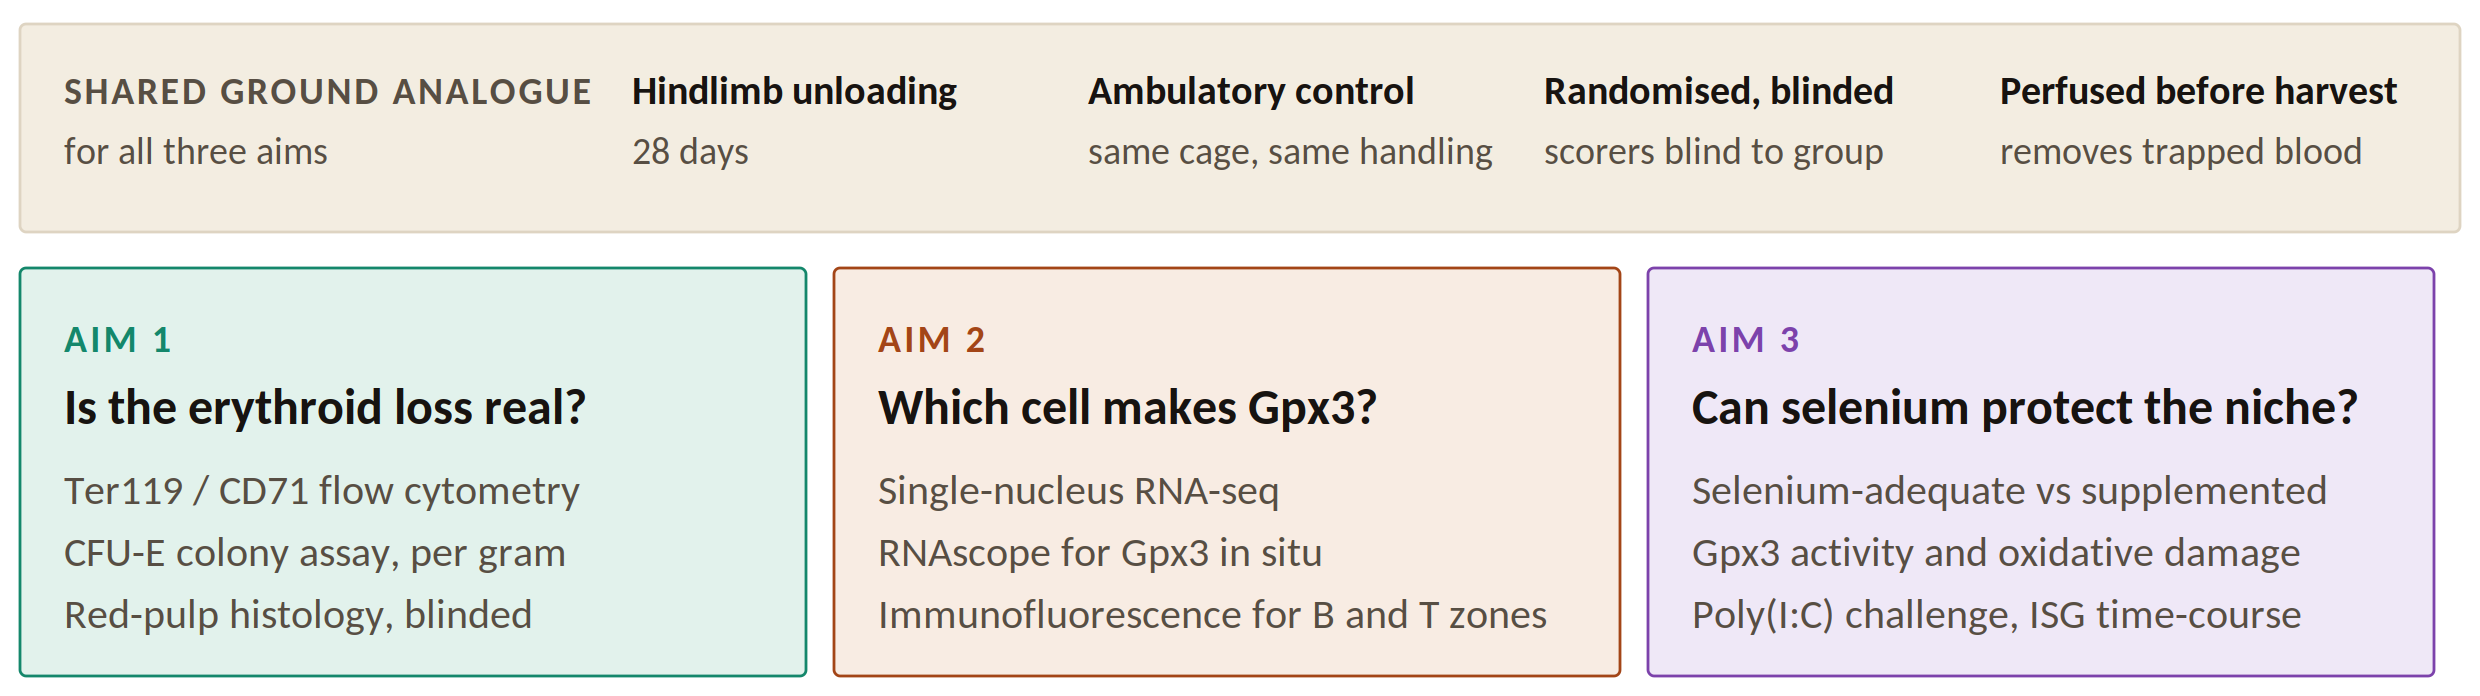

figures/fig_contamination.png   (192 KB)


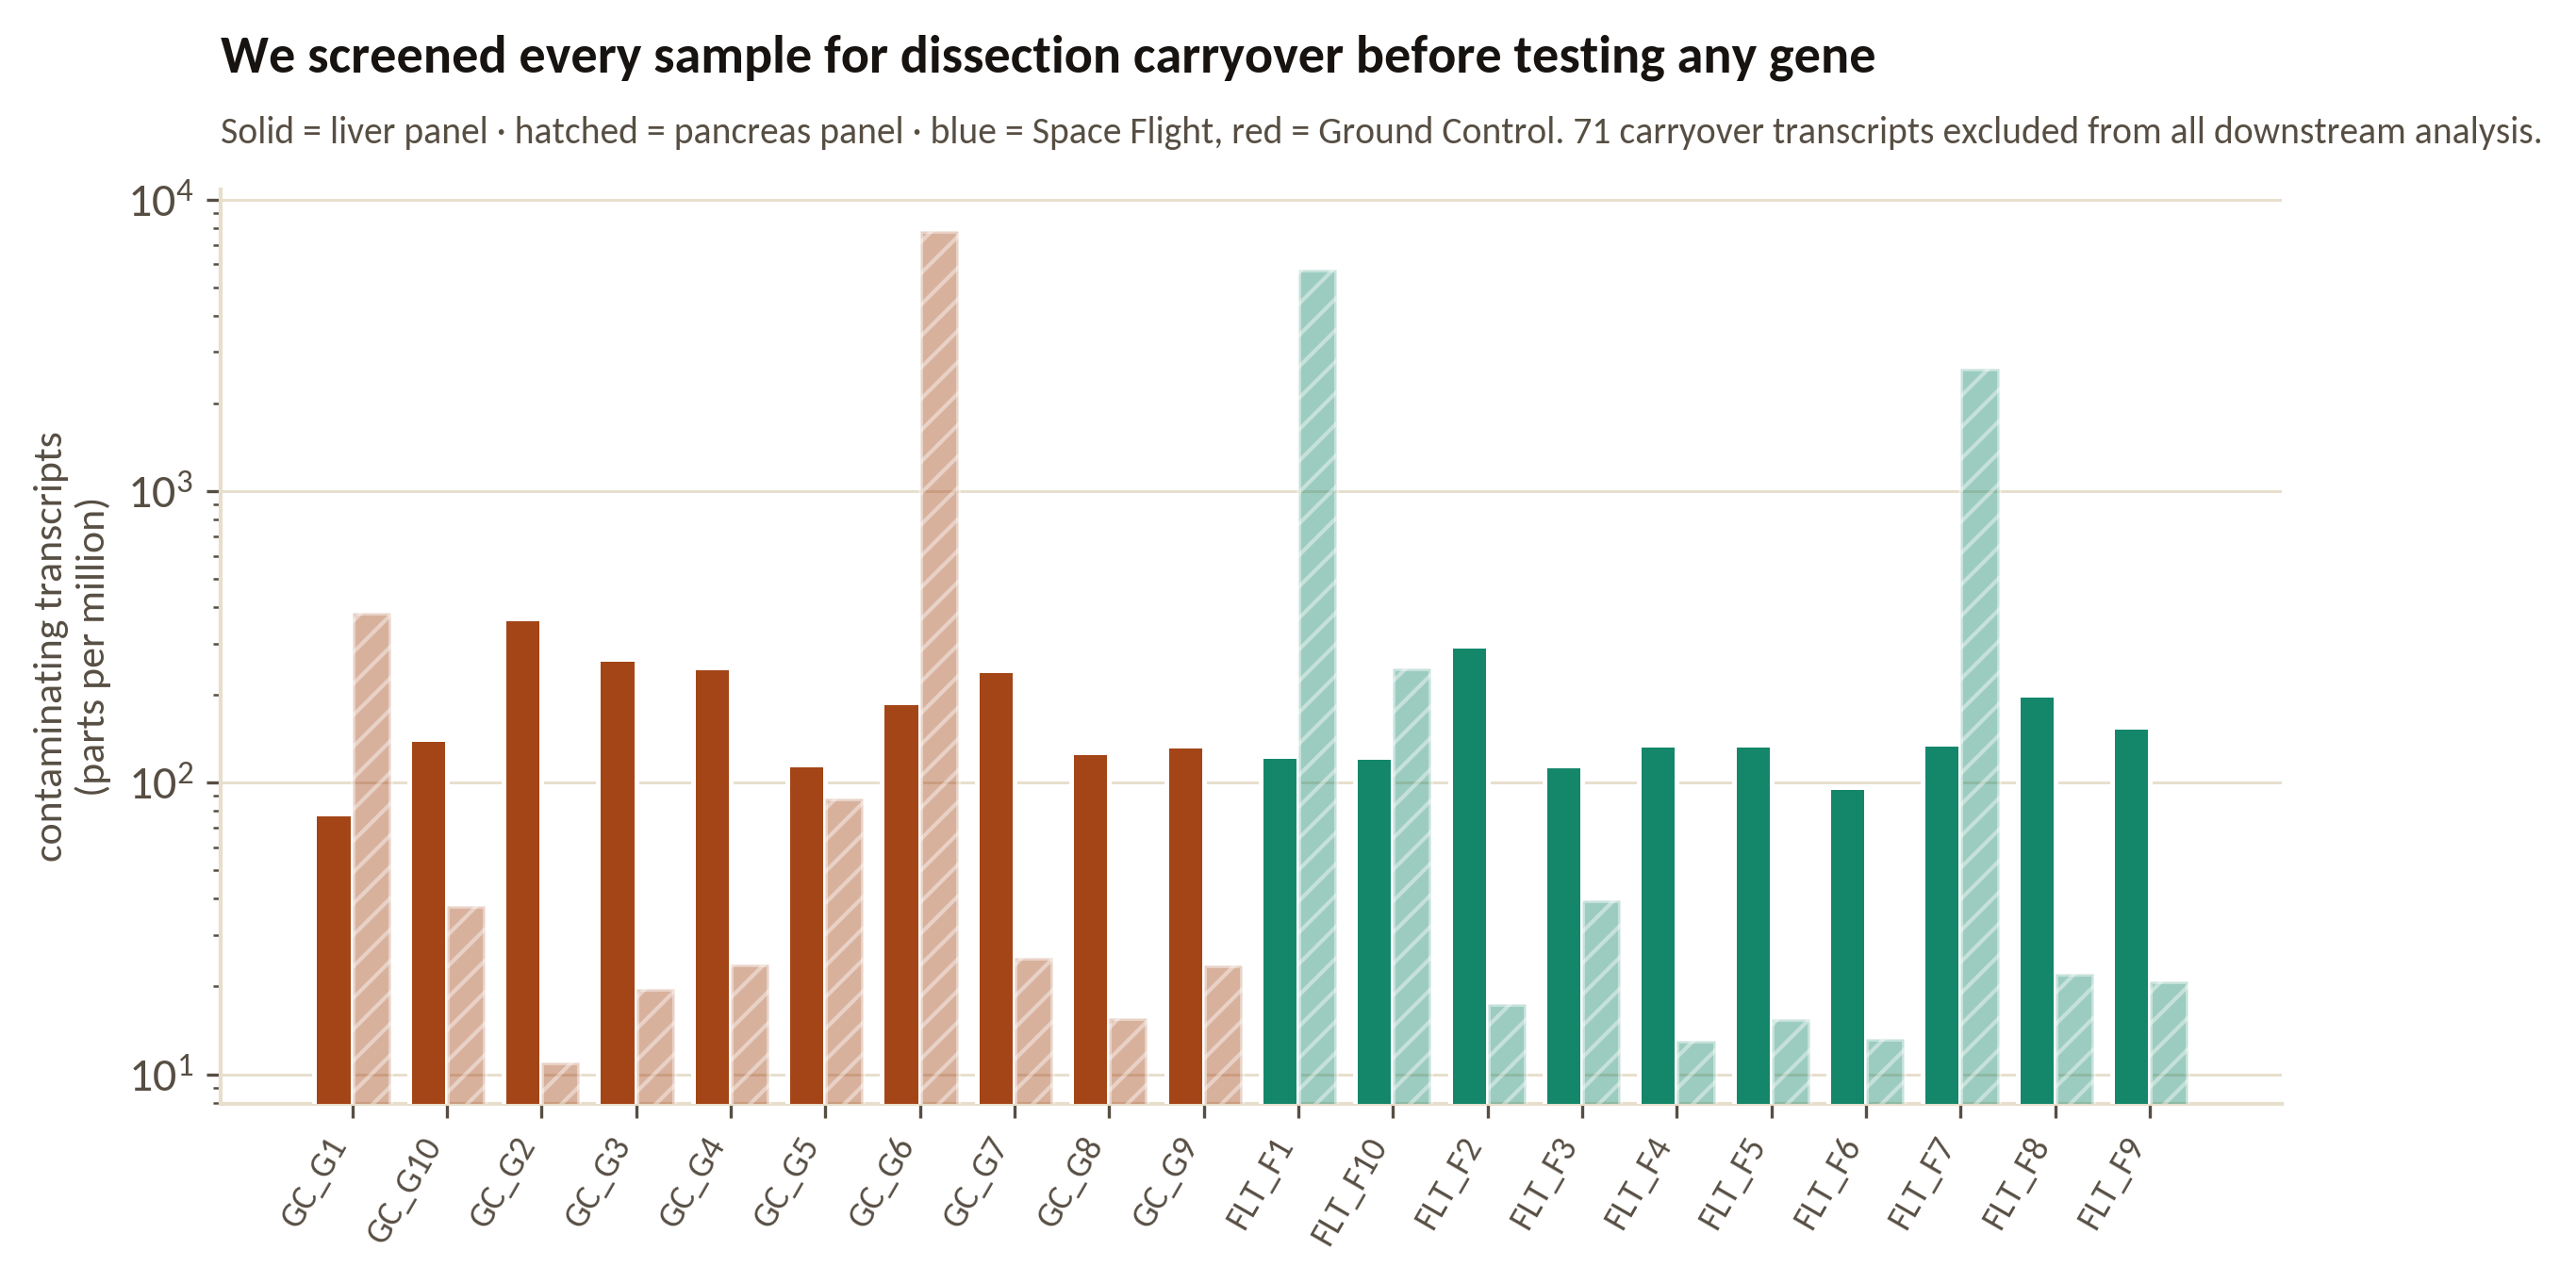

figures/fig_expected.png   (79 KB)


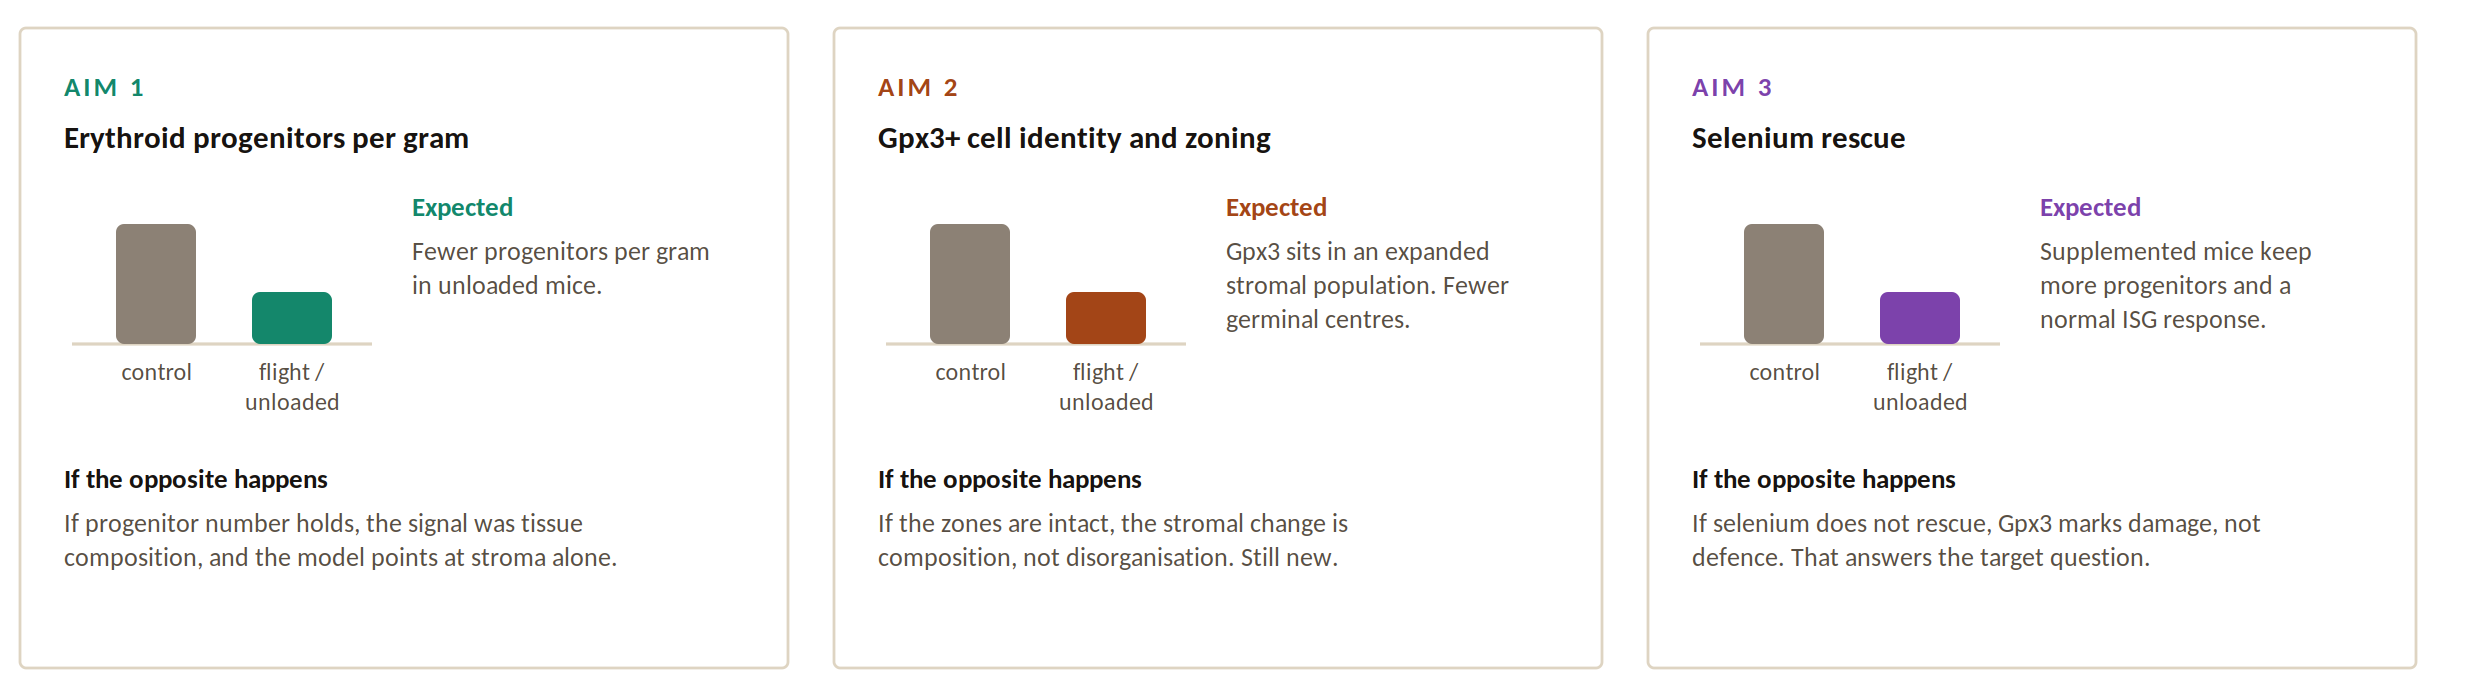

figures/fig_gsea.png   (198 KB)


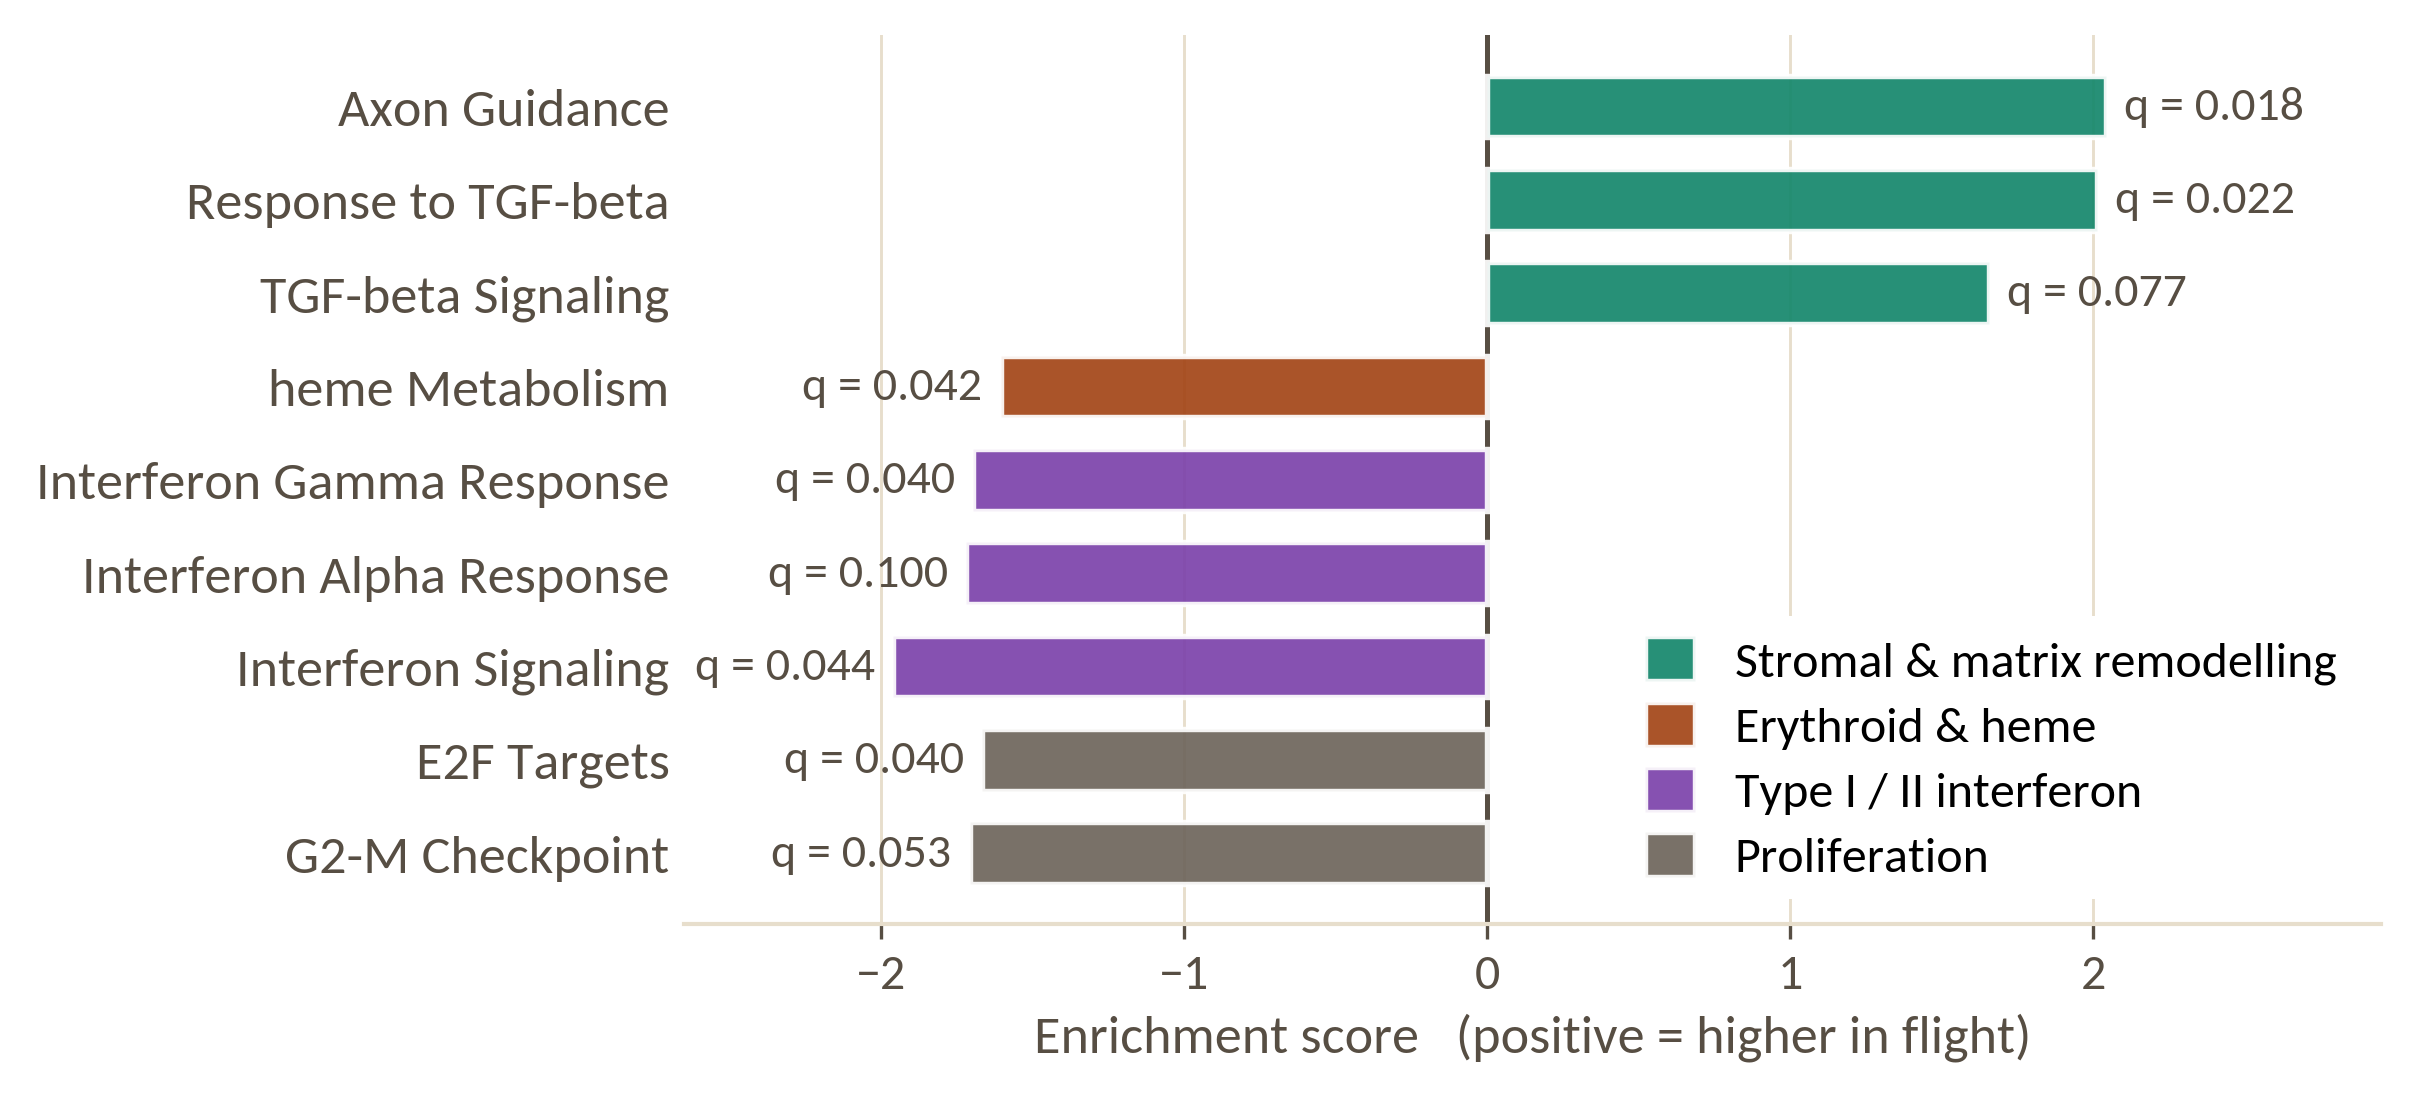

figures/fig_heme.png   (98 KB)


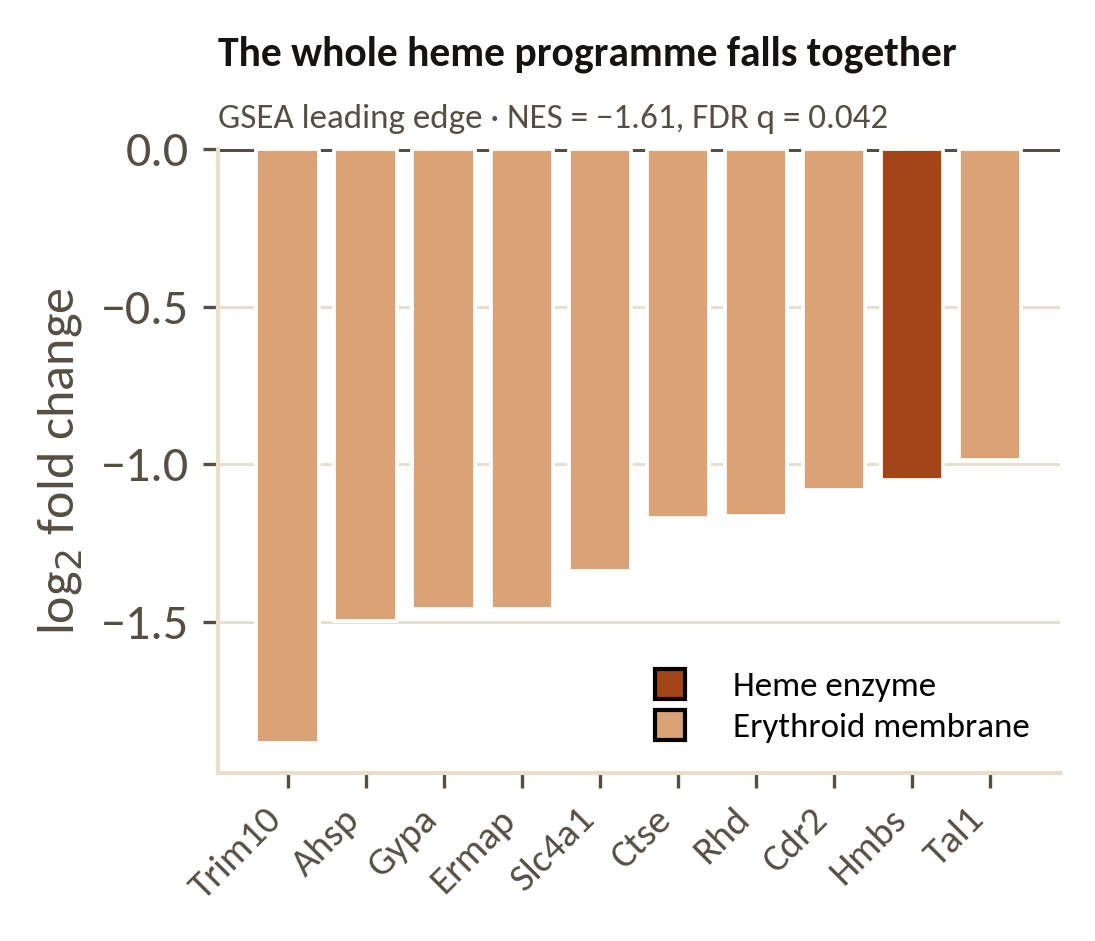

figures/fig_mission.png   (175 KB)


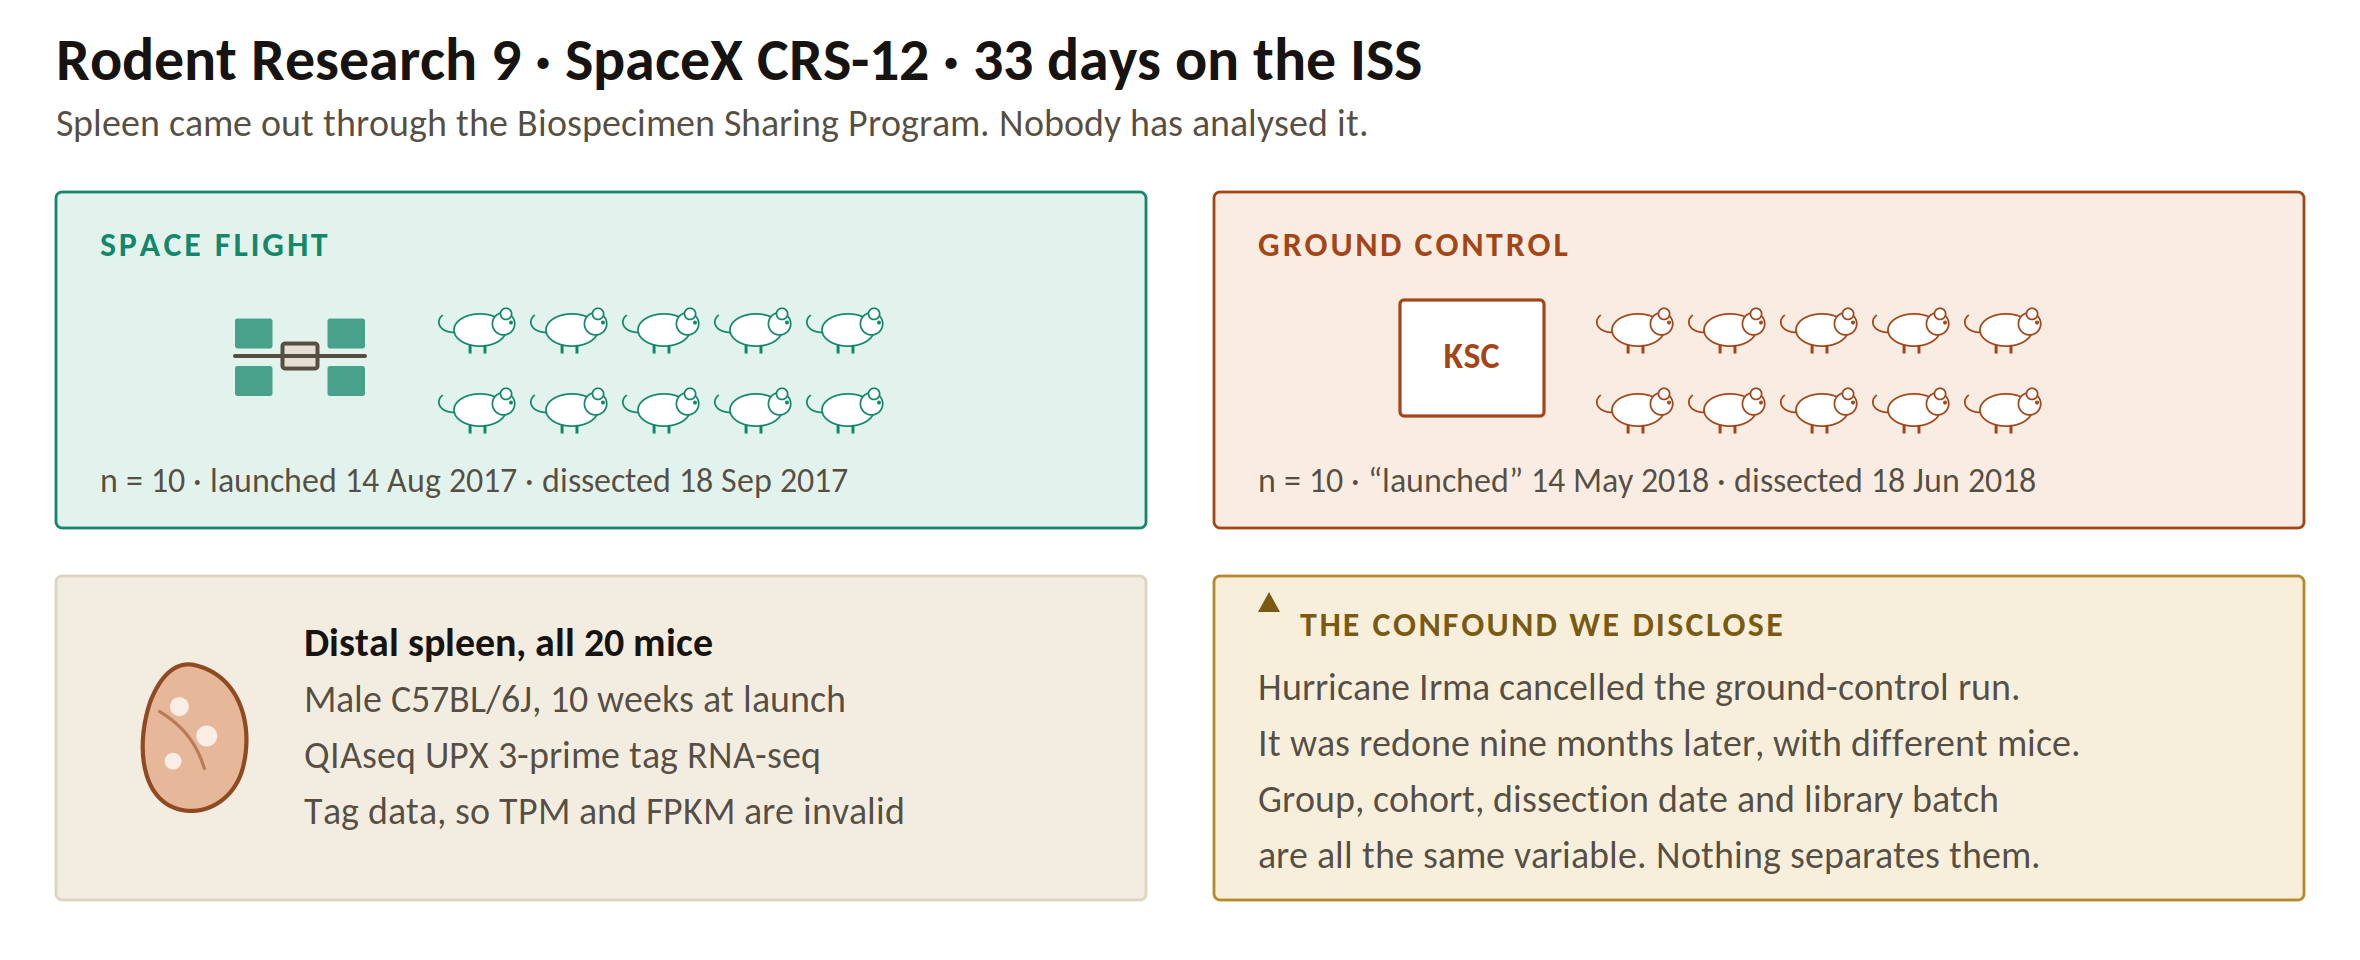

figures/fig_model.png   (142 KB)


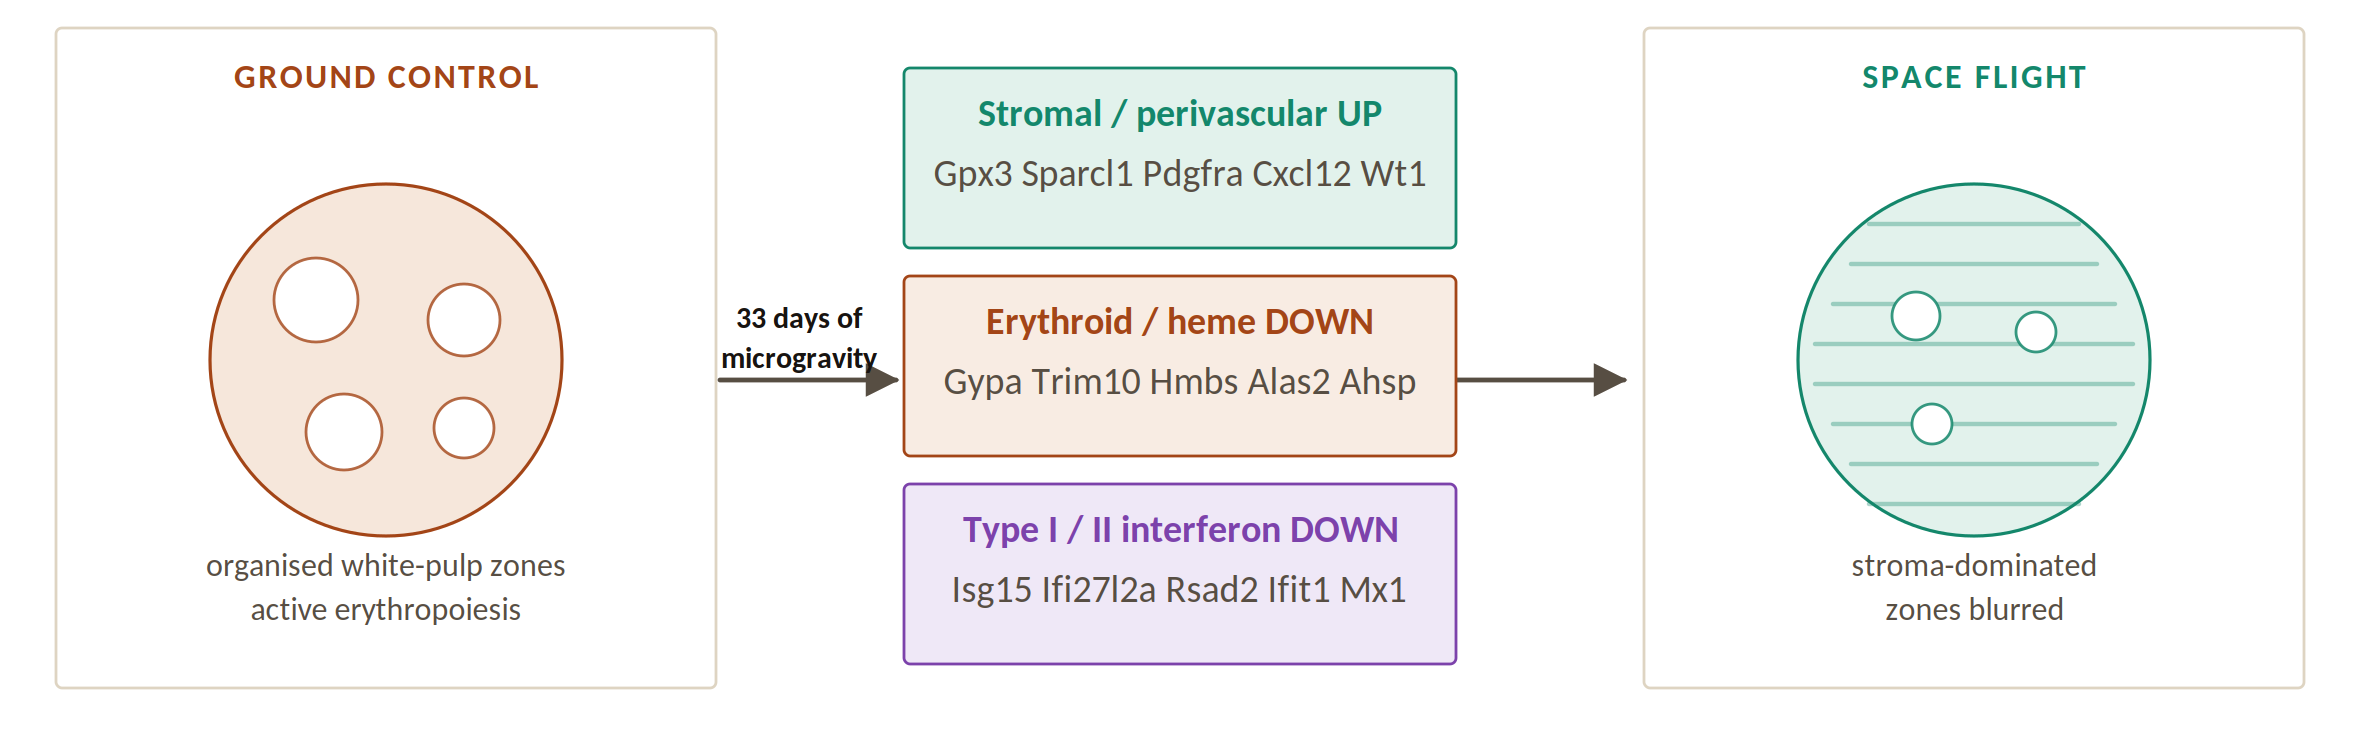

figures/fig_pipeline.png   (86 KB)


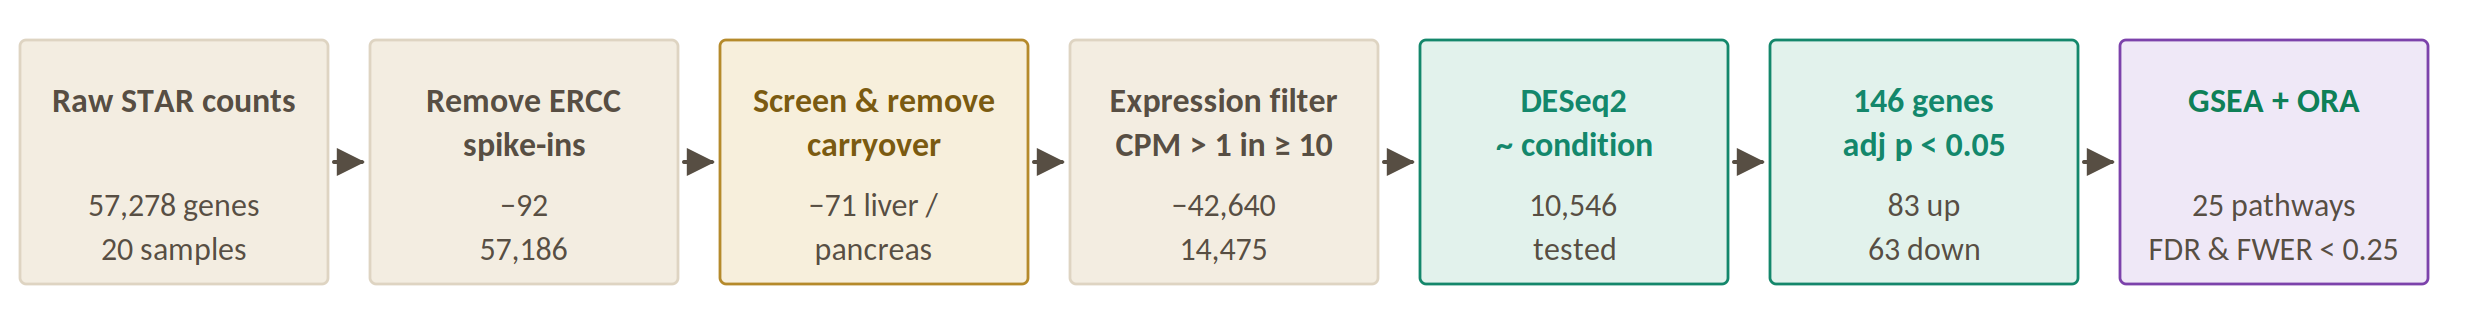

figures/fig_qc_pca.png   (187 KB)


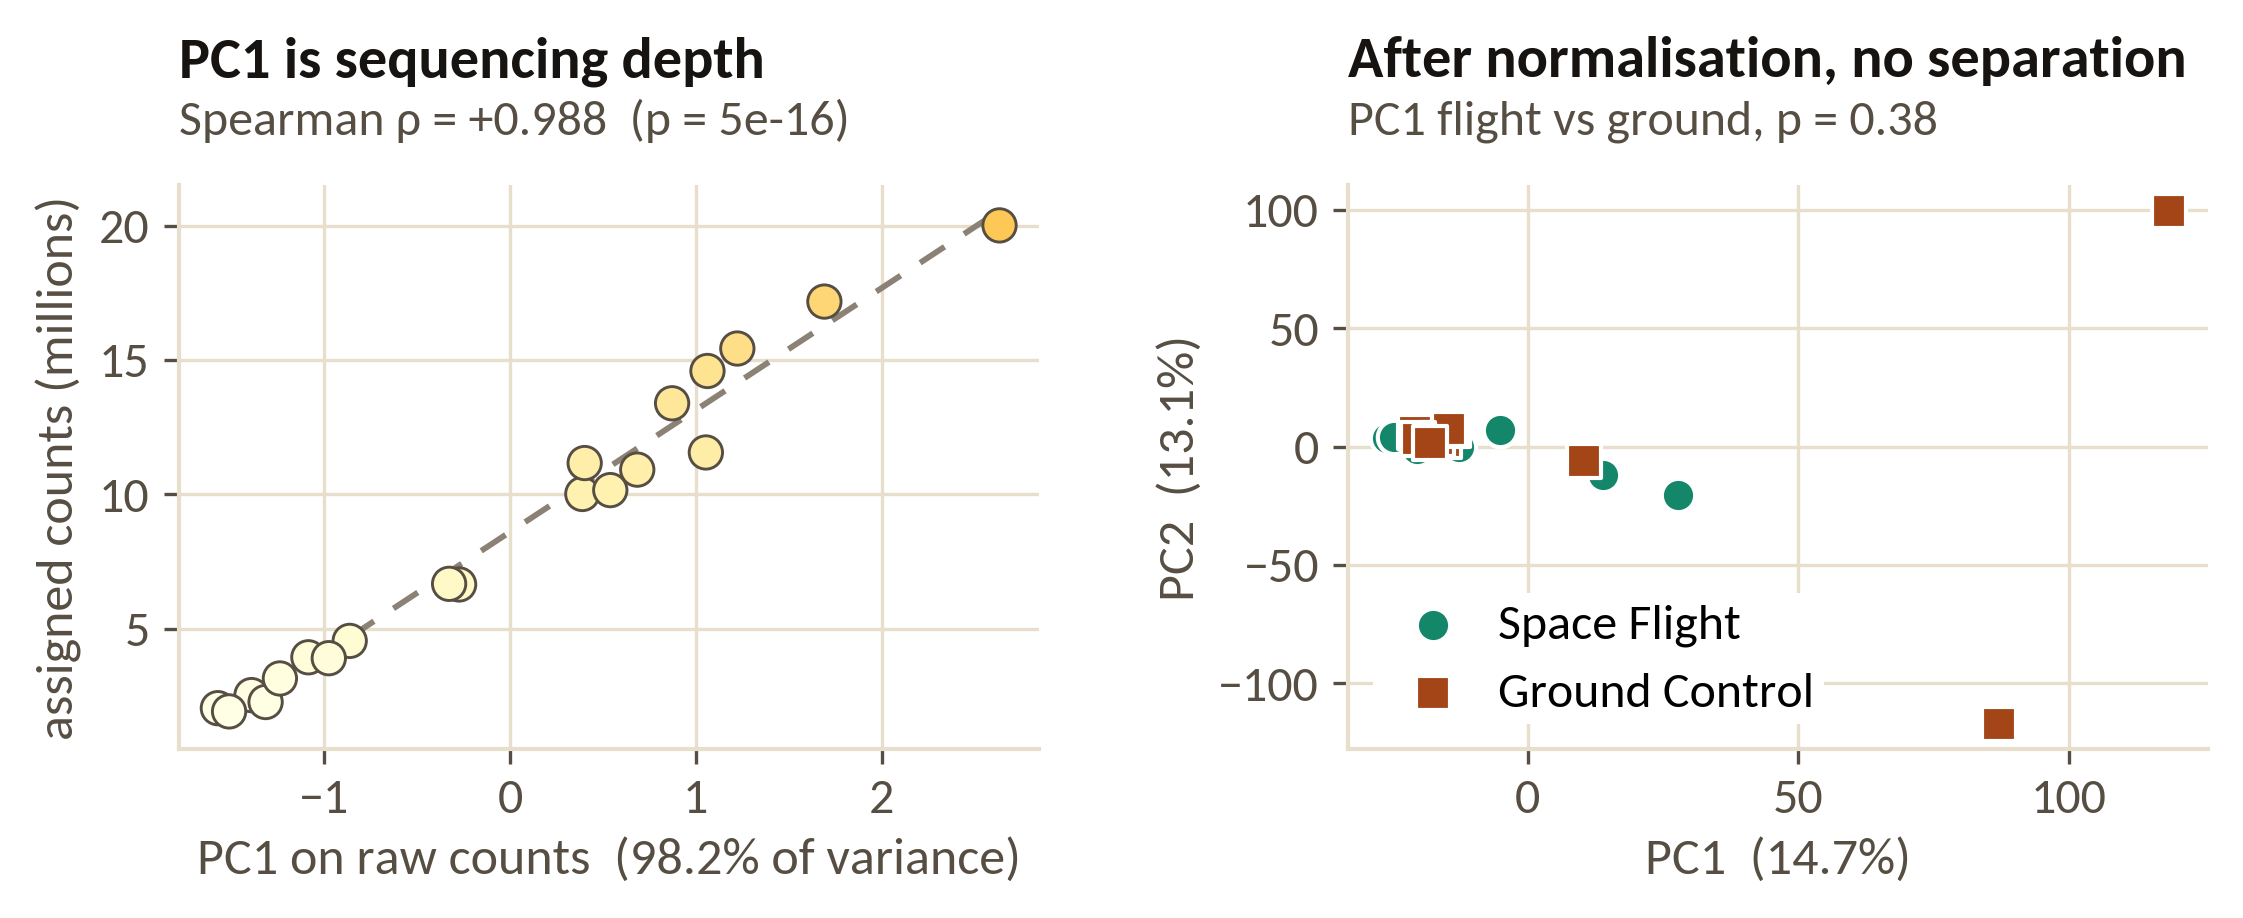

figures/fig_three_modules.png   (130 KB)


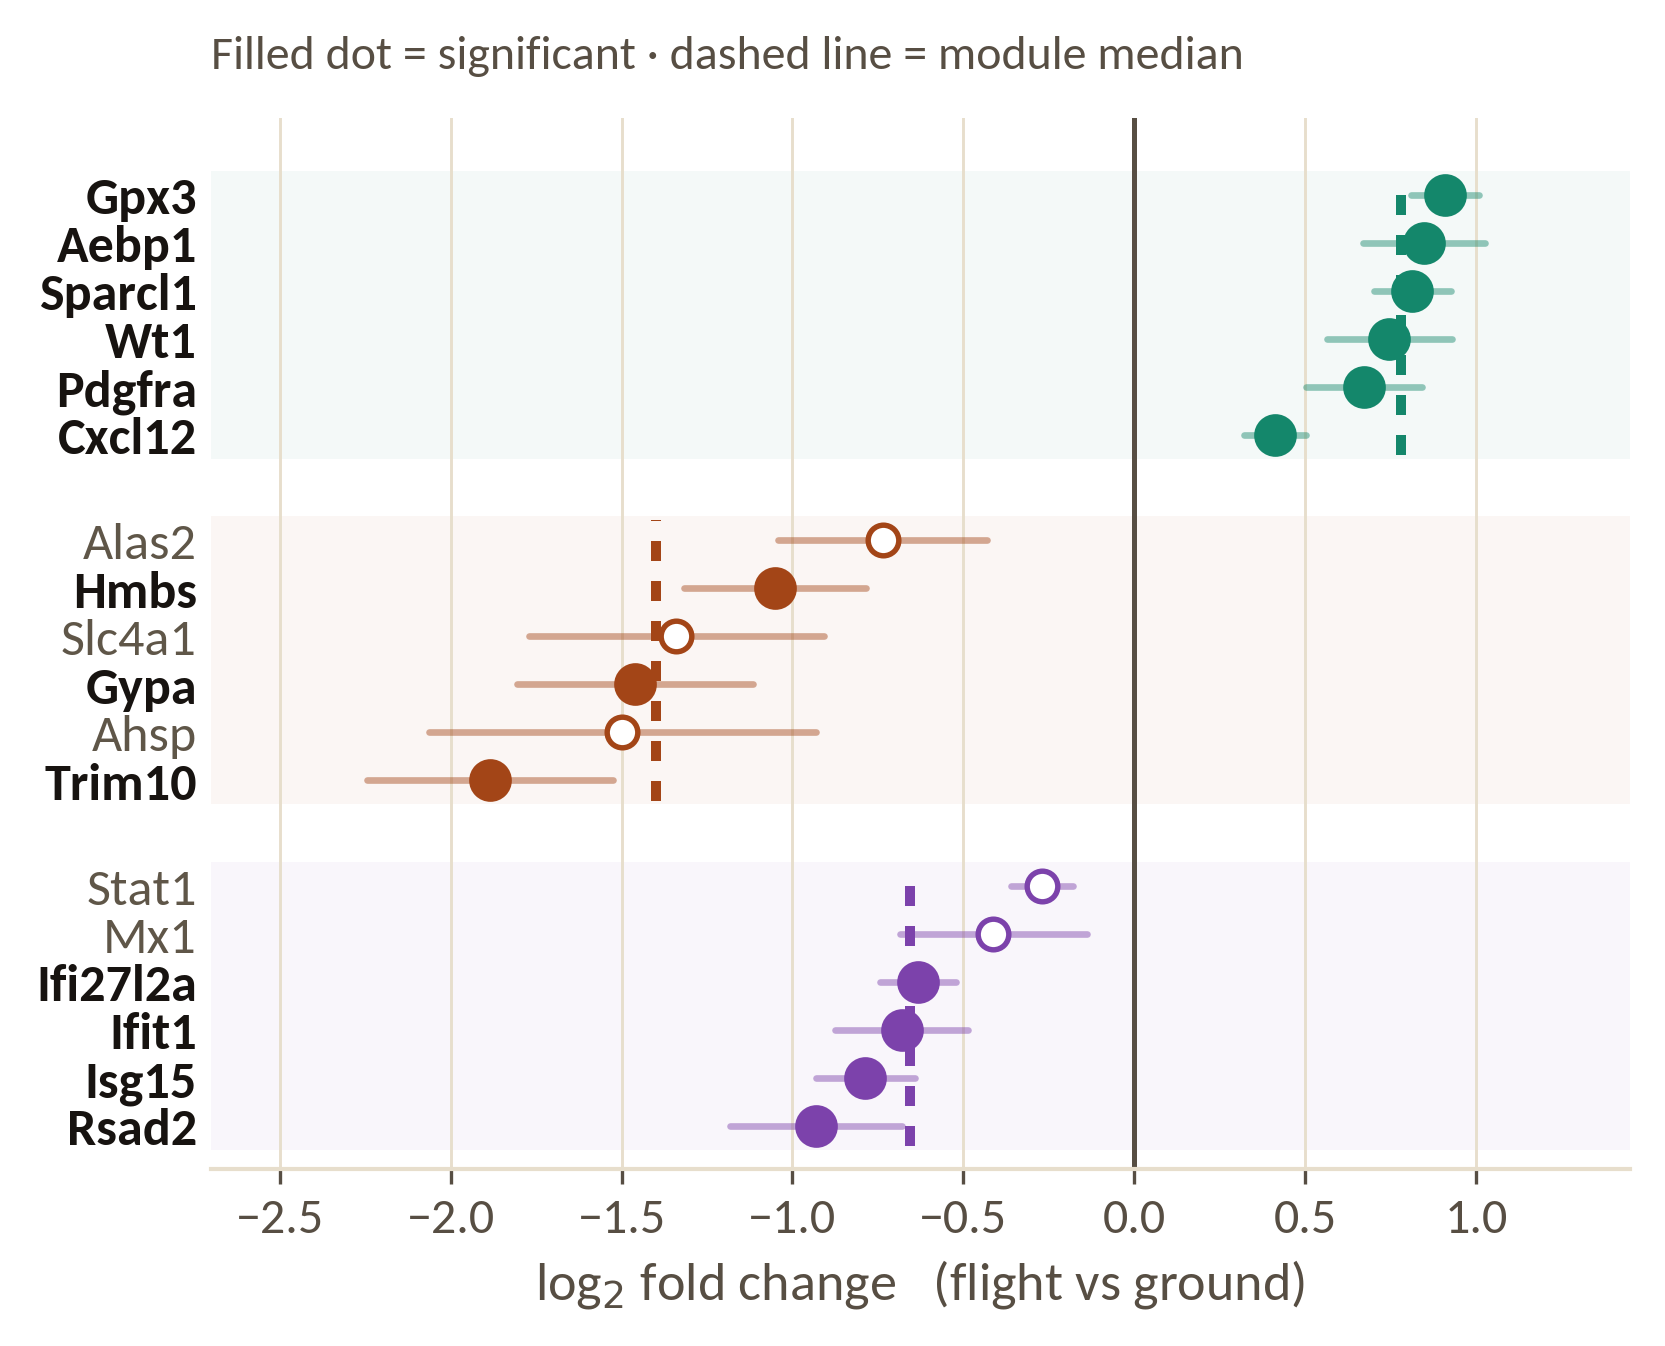

figures/fig_volcano.png   (179 KB)


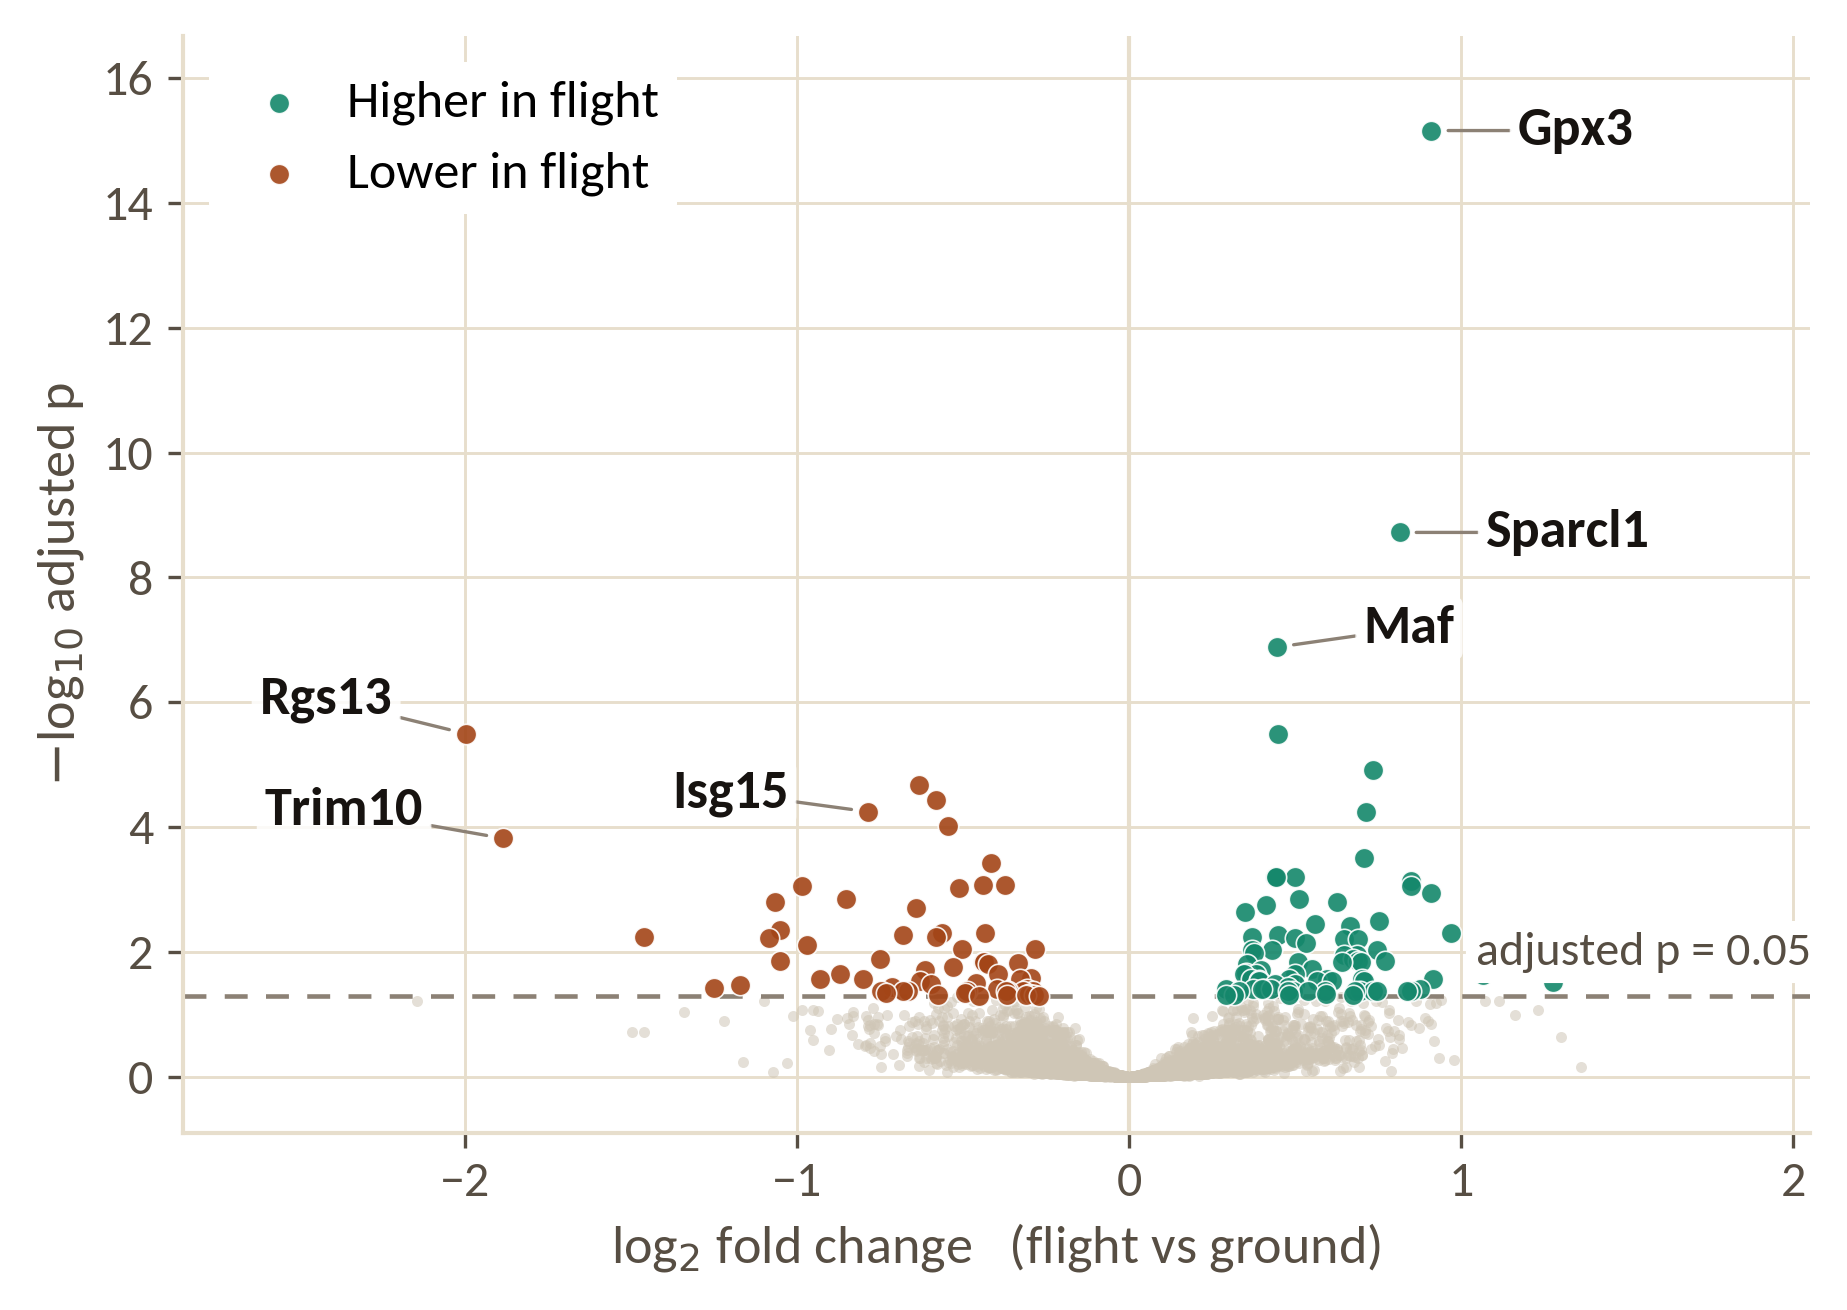

In [9]:
import glob
from IPython.display import Image, display
for f in sorted(glob.glob(f"{FIG}/*.png")):
    print(f"{f}   ({os.path.getsize(f)/1024:.0f} KB)")
    display(Image(filename=f, width=900))